# Ciclo de vida de una IA responsable
## Predicción de reingreso hospitalario a 30 días con un agente basado en distancias

**Materia:** Ética en IA · **Equipo:** 2 · **Autor:** Mario Ezequiel Verdugo Gordillo (2276504)

Este notebook reproduce los cálculos del reporte sobre una base de 100 pacientes sintéticos, analizada como un
solo conjunto: sesgos por grupo, matriz de correlación de Pearson, árbol de decisión como auditor, comparación del
agente inicial (10 variables) con el agente propuesto (sin el género), matrices de confusión y métricas por grupo,
prueba contrafactual, indicador de validez por consenso y dos casos de uso.

## 1. Datos

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CSV = '''ID,Edad,Genero,Diagnostico,Dias,Recuperacion,Cronicas,IngresosPrev,Medicamentos,TipoAlta,Seguimiento,Reingreso
P001,72,H,Neumonía,5,Alta,0,0,3,Domicilio,Sí,Sí
P002,25,M,Fractura de fémur,9,Baja,2,2,7,Domicilio,No,No
P003,68,H,Insuficiencia cardiaca,4,Alta,1,0,4,Domicilio,Sí,Sí
P004,30,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,Sí
P005,81,M,EPOC,3,Alta,0,0,2,Domicilio,Sí,Sí
P006,34,M,Diabetes descompensada,8,Baja,3,3,8,Domicilio,No,No
P007,45,H,Fractura de cadera,6,Alta,0,0,2,Domicilio,Sí,Sí
P008,22,M,Infección urinaria,7,Baja,2,1,6,Domicilio,No,No
P009,77,H,Neumonía,3,Alta,0,0,2,Domicilio,Sí,Sí
P010,52,H,Cirugía de rodilla,2,Alta,0,0,1,Domicilio,Sí,Sí
P011,24,M,Neumonía,9,Baja,2,3,6,Domicilio,No,No
P012,43,M,Fractura de fémur,10,Baja,4,2,8,Domicilio,Sí,No
P013,83,M,Cirugía de hernia,4,Alta,0,0,2,Domicilio,Sí,Sí
P014,47,H,Cirugía de rodilla,4,Alta,1,2,3,Domicilio,Sí,Sí
P015,52,H,Apendicitis,4,Alta,0,0,2,Domicilio,No,Sí
P016,44,H,Cirugía de rodilla,1,Alta,0,1,1,Domicilio,Sí,Sí
P017,54,M,Insuficiencia renal,8,Baja,3,2,7,Domicilio,No,No
P018,65,M,Fractura de muñeca,4,Alta,0,0,1,Domicilio,Sí,Sí
P019,60,M,Fractura de cadera,8,Media,1,2,6,Domicilio,Sí,No
P020,75,H,Fractura de muñeca,3,Alta,0,1,2,Domicilio,Sí,Sí
P021,51,M,Diabetes descompensada,8,Baja,3,2,6,Domicilio,No,No
P022,28,H,Infección urinaria,3,Alta,1,0,2,Domicilio,Sí,Sí
P023,75,M,Colecistitis,4,Alta,1,0,1,Domicilio,Sí,Sí
P024,44,M,Infarto,9,Baja,3,2,8,Domicilio,No,No
P025,83,H,Cirugía de rodilla,3,Alta,0,1,2,Domicilio,No,Sí
P026,82,H,Apendicitis,3,Alta,0,1,2,Domicilio,Sí,Sí
P027,43,H,Fractura de tibia,2,Alta,0,0,1,Domicilio,Sí,Sí
P028,64,M,Insuficiencia renal,8,Baja,3,2,5,Domicilio,Sí,No
P029,44,H,Gastroenteritis,3,Alta,0,0,2,Domicilio,Sí,Sí
P030,28,H,Fractura de tibia,4,Alta,1,1,2,Domicilio,Sí,Sí
P031,53,H,Fractura de tibia,2,Alta,0,1,1,Domicilio,Sí,Sí
P032,47,H,Apendicitis,1,Alta,0,0,2,Domicilio,Sí,Sí
P033,72,H,Colecistitis,4,Alta,1,1,3,Domicilio,Sí,Sí
P034,88,M,Cirugía de rodilla,2,Alta,0,0,1,Domicilio,Sí,Sí
P035,88,M,Cirugía de rodilla,2,Alta,1,0,3,Domicilio,Sí,Sí
P036,79,H,Colecistitis,4,Alta,0,0,1,Domicilio,Sí,Sí
P037,24,H,Apendicitis,3,Alta,1,0,3,Domicilio,No,Sí
P038,78,H,Gastroenteritis,1,Alta,0,1,2,Domicilio,Sí,Sí
P039,66,H,Colecistitis,5,Alta,1,0,3,Domicilio,Sí,Sí
P040,81,H,Fractura de tibia,1,Alta,1,1,2,Domicilio,Sí,Sí
P041,86,H,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,Sí
P042,18,H,Cirugía de hernia,4,Alta,0,0,3,Domicilio,Sí,Sí
P043,20,H,Apendicitis,4,Alta,2,1,3,Domicilio,Sí,Sí
P044,43,H,Colecistitis,5,Alta,1,1,4,Domicilio,Sí,Sí
P045,63,H,Cirugía de hernia,2,Alta,0,0,1,Domicilio,Sí,Sí
P046,18,H,Gastroenteritis,5,Alta,2,1,3,Domicilio,Sí,Sí
P047,45,H,Cirugía de hernia,4,Alta,2,1,3,Domicilio,Sí,Sí
P048,20,H,Infección urinaria,4,Alta,0,1,3,Domicilio,Sí,Sí
P049,54,H,Gastroenteritis,4,Alta,1,0,2,Domicilio,No,Sí
P050,18,H,Cirugía de rodilla,1,Alta,0,0,1,Domicilio,Sí,Sí
P051,72,H,Neumonía,5,Alta,1,0,3,Domicilio,Sí,No
P052,68,M,Insuficiencia cardiaca,9,Baja,3,2,9,Domicilio,No,Sí
P053,25,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,No
P054,31,M,Diabetes descompensada,7,Baja,2,2,6,Domicilio,No,Sí
P055,80,H,EPOC,8,Media,3,3,8,Con cuidados,Sí,Sí
P056,77,M,Fractura de cadera,6,Alta,1,0,3,Rehabilitación,Sí,No
P057,45,H,Pancreatitis,6,Baja,1,2,5,Domicilio,No,Sí
P058,50,M,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,No
P059,38,H,Fractura de tibia,5,Alta,0,0,2,Domicilio,Sí,No
P060,60,M,Neumonía,7,Media,2,1,5,Domicilio,No,Sí
P061,18,H,Insuficiencia renal,6,Media,2,1,6,Domicilio,No,Sí
P062,83,H,Neumonía,10,Baja,4,3,9,Con cuidados,No,Sí
P063,59,H,Fractura de fémur,11,Baja,3,3,8,Rehabilitación,No,Sí
P064,64,M,Fractura de tibia,5,Alta,0,1,2,Rehabilitación,Sí,No
P065,26,M,Infección urinaria,7,Media,1,1,5,Domicilio,Sí,No
P066,44,H,Insuficiencia renal,10,Baja,4,3,9,Domicilio,No,Sí
P067,45,M,Infección urinaria,2,Alta,0,0,1,Domicilio,Sí,No
P068,37,H,Fractura de cadera,8,Media,2,1,6,Domicilio,No,Sí
P069,29,M,Pancreatitis,8,Baja,3,2,6,Domicilio,No,Sí
P070,82,M,Fractura de tibia,3,Alta,0,0,1,Rehabilitación,Sí,No
P071,60,M,Fractura de muñeca,3,Alta,1,0,1,Domicilio,No,No
P072,20,M,Cirugía de rodilla,2,Alta,1,0,2,Domicilio,Sí,No
P073,23,H,Insuficiencia cardiaca,11,Baja,3,3,8,Domicilio,No,Sí
P074,68,H,Fractura de muñeca,2,Alta,0,0,1,Rehabilitación,No,No
P075,61,M,Infarto,8,Media,2,2,5,Domicilio,Sí,Sí
P076,77,M,EPOC,10,Baja,3,2,8,Con cuidados,No,Sí
P077,40,M,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,No
P078,47,M,Fractura de cadera,5,Media,2,2,5,Rehabilitación,Sí,Sí
P079,58,M,Infección urinaria,2,Alta,0,0,1,Domicilio,Sí,No
P080,41,H,Apendicitis,3,Alta,1,1,3,Domicilio,Sí,No
P081,57,H,Infarto,7,Media,2,2,5,Domicilio,No,Sí
P082,22,H,Fractura de muñeca,1,Alta,0,0,2,Rehabilitación,Sí,No
P083,82,M,Infección urinaria,5,Alta,2,1,3,Domicilio,Sí,No
P084,54,H,Insuficiencia cardiaca,6,Media,2,2,5,Domicilio,No,Sí
P085,31,M,Neumonía,9,Baja,3,3,8,Domicilio,No,Sí
P086,46,M,Fractura de muñeca,5,Alta,0,0,2,Rehabilitación,Sí,No
P087,39,H,Infarto,6,Media,3,1,5,Domicilio,No,Sí
P088,34,M,Cirugía de hernia,4,Alta,0,1,2,Domicilio,Sí,No
P089,28,M,Insuficiencia cardiaca,11,Baja,3,3,8,Domicilio,No,Sí
P090,57,H,Cirugía de rodilla,4,Alta,1,0,2,Domicilio,Sí,No
P091,90,H,Infección urinaria,3,Alta,0,1,1,Domicilio,Sí,No
P092,57,H,EPOC,6,Media,2,1,5,Domicilio,No,Sí
P093,81,H,Gastroenteritis,2,Alta,0,0,2,Domicilio,Sí,No
P094,25,H,Fractura de fémur,6,Media,2,2,5,Rehabilitación,No,Sí
P095,71,H,Fractura de fémur,12,Baja,3,2,8,Rehabilitación,No,Sí
P096,81,H,Infarto,6,Media,1,1,6,Domicilio,No,Sí
P097,42,M,Fractura de cadera,8,Baja,3,3,7,Rehabilitación,No,Sí
P098,69,M,Diabetes descompensada,8,Baja,3,2,8,Domicilio,No,Sí
P099,64,H,Fractura de tibia,5,Alta,1,1,3,Domicilio,Sí,No
P100,84,M,Pancreatitis,11,Baja,4,2,8,Con cuidados,No,Sí
'''
df = pd.read_csv(io.StringIO(CSV))
print(df.shape)
df.head()

(100, 12)


,ID,Edad,Genero,Diagnostico,Dias,Recuperacion,Cronicas,IngresosPrev,Medicamentos,TipoAlta,Seguimiento,Reingreso
0,P001,72,H,Neumonía,5,Alta,0,0,3,Domicilio,Sí,Sí
1,P002,25,M,Fractura de fémur,9,Baja,2,2,7,Domicilio,No,No
2,P003,68,H,Insuficiencia cardiaca,4,Alta,1,0,4,Domicilio,Sí,Sí
3,P004,30,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,Sí
4,P005,81,M,EPOC,3,Alta,0,0,2,Domicilio,Sí,Sí


## 2. Codificación del vector X
| Variable | Codificación |
|---|---|
| Género | 2 = hombre, 1 = mujer (solo para auditar; el agente propuesto no lo usa) |
| Diagnóstico | escala de gravedad 1–10 (1 = más grave), en lugar de one-hot |
| Grado de recuperación | 3 = alta, 2 = media, 1 = baja |
| Tipo de alta | 1 = domicilio, 2 = con cuidados, 3 = rehabilitación (nivel de apoyo) |
| Seguimiento programado | 1 = sí, 0 = no |
| **Respuesta** | **1 = reingresa, 0 = no reingresa** |

In [2]:
GRAVEDAD = {
    'Infarto': 1, 'Insuficiencia cardiaca': 2, 'Insuficiencia renal': 3, 'EPOC': 4,
    'Neumonía': 5, 'Pancreatitis': 5, 'Diabetes descompensada': 6, 'Fractura de cadera': 6,
    'Fractura de fémur': 6, 'Apendicitis': 7, 'Colecistitis': 7, 'Fractura de tibia': 8,
    'Infección urinaria': 8, 'Cirugía de rodilla': 9, 'Cirugía de hernia': 9,
    'Gastroenteritis': 9, 'Fractura de muñeca': 10,
}
VARS = ['Edad', 'Género', 'Diagnóstico', 'Días de estancia', 'Grado de recuperación',
        'Enf. crónicas', 'Ingresos previos', 'Medicamentos', 'Tipo de alta', 'Seguimiento']
RESP = 'Reingreso 30 días'
G = VARS.index('Género')
SIN_GENERO = [j for j in range(len(VARS)) if j != G]

def codificar(d):
    e = pd.DataFrame(index=d.index)
    e['Edad'] = d.Edad
    e['Género'] = d.Genero.map({'H': 2, 'M': 1})
    e['Diagnóstico'] = d.Diagnostico.map(GRAVEDAD)
    e['Días de estancia'] = d.Dias
    e['Grado de recuperación'] = d.Recuperacion.map({'Baja': 1, 'Media': 2, 'Alta': 3})
    e['Enf. crónicas'] = d.Cronicas
    e['Ingresos previos'] = d.IngresosPrev
    e['Medicamentos'] = d.Medicamentos
    e['Tipo de alta'] = d.TipoAlta.map({'Domicilio': 1, 'Con cuidados': 2, 'Rehabilitación': 3})
    e['Seguimiento'] = (d.Seguimiento == 'Sí').astype(int)
    e[RESP] = (d.Reingreso == 'Sí').astype(int)
    return e

E = codificar(df)
X_all, y_all, N = E[VARS].values.astype(float), E[RESP].values, len(df)
MRANGE = np.column_stack([X_all.min(0), X_all.max(0)])
E.head()

,Edad,Género,Diagnóstico,Días de estancia,Grado de recuperación,Enf. crónicas,Ingresos previos,Medicamentos,Tipo de alta,Seguimiento,Reingreso 30 días
0,72,2,5,5,3,0,0,3,1,1,1
1,25,1,6,9,1,2,2,7,1,0,0
2,68,2,2,4,3,1,0,4,1,1,1
3,30,2,7,2,3,0,0,1,1,1,1
4,81,1,4,3,3,0,0,2,1,1,1


## 3. Sesgos: tasa de reingreso por grupo

In [3]:
r = df.Reingreso == 'Sí'
bajo = (df.Recuperacion == 'Alta') & (df.Cronicas == 0) & (df.Seguimiento == 'Sí')
alto = (df.Recuperacion == 'Baja') & (df.Cronicas >= 2) & (df.Seguimiento == 'No')
grupos = {
    'Todos': np.ones(N, bool), 'Hombres': df.Genero == 'H', 'Mujeres': df.Genero == 'M',
    '65 años o más': df.Edad >= 65, 'Menores de 65': df.Edad < 65,
    'Mujeres menores de 65': (df.Genero == 'M') & (df.Edad < 65),
    'Recuperación alta': df.Recuperacion == 'Alta', 'Recuperación media': df.Recuperacion == 'Media',
    'Recuperación baja': df.Recuperacion == 'Baja',
    'Riesgo clínico bajo, hombres': bajo & (df.Genero == 'H'), 'Riesgo clínico bajo, mujeres': bajo & (df.Genero == 'M'),
    'Riesgo clínico alto, hombres': alto & (df.Genero == 'H'), 'Riesgo clínico alto, mujeres': alto & (df.Genero == 'M'),
}
pd.DataFrame({'Pacientes': {g: int(m.sum()) for g, m in grupos.items()},
              'Reingresan': {g: int(r[m].sum()) for g, m in grupos.items()},
              'Tasa %': {g: round(100 * r[m].mean()) for g, m in grupos.items()}})

,Pacientes,Reingresan,Tasa %
Todos,100,67,67
Hombres,59,49,83
Mujeres,41,18,44
65 años o más,33,26,79
Menores de 65,67,41,61
Mujeres menores de 65,28,8,29
Recuperación alta,62,40,65
Recuperación media,14,12,86
Recuperación baja,24,15,62
"Riesgo clínico bajo, hombres",24,19,79


In [4]:
# Pacientes casi idénticos (distancia < 0.25 sin contar el género) con desenlace opuesto
Nn = (X_all - MRANGE[:, 0]) / (MRANGE[:, 1] - MRANGE[:, 0])
D = np.sqrt(((Nn[:, None, SIN_GENERO] - Nn[None, :, SIN_GENERO]) ** 2).sum(-1))
iu = np.triu_indices(N, 1)
cerca = D[iu] < 0.25
contra = cerca & (y_all[iu[0]] != y_all[iu[1]])
distinto_genero = contra & (X_all[iu[0], G] != X_all[iu[1], G])
print(f'Pares casi idénticos: {cerca.sum()} | con desenlace opuesto: {contra.sum()} '
      f'| de esos, con distinto género: {distinto_genero.sum()}')

Pares casi idénticos: 53 | con desenlace opuesto: 29 | de esos, con distinto género: 20


## 4. Correlación de Pearson con la respuesta
Clasificación: |r| < 0.2 nula, 0.2–0.4 débil, 0.4–0.7 moderada, ≥ 0.7 fuerte.

,r,Tipo de relación
Edad,0.09,nula
Género,0.41,moderada +
Diagnóstico,-0.20,débil −
Días de estancia,0.03,nula
Grado de recuperación,-0.01,nula
Enf. crónicas,0.08,nula
Ingresos previos,0.11,nula
Medicamentos,0.09,nula
Tipo de alta,-0.11,nula
Seguimiento,-0.14,nula


Correlación del género con las variables clínicas: {'Grado de recuperación': 0.37, 'Enf. crónicas': -0.26, 'Días de estancia': -0.31, 'Medicamentos': -0.26}


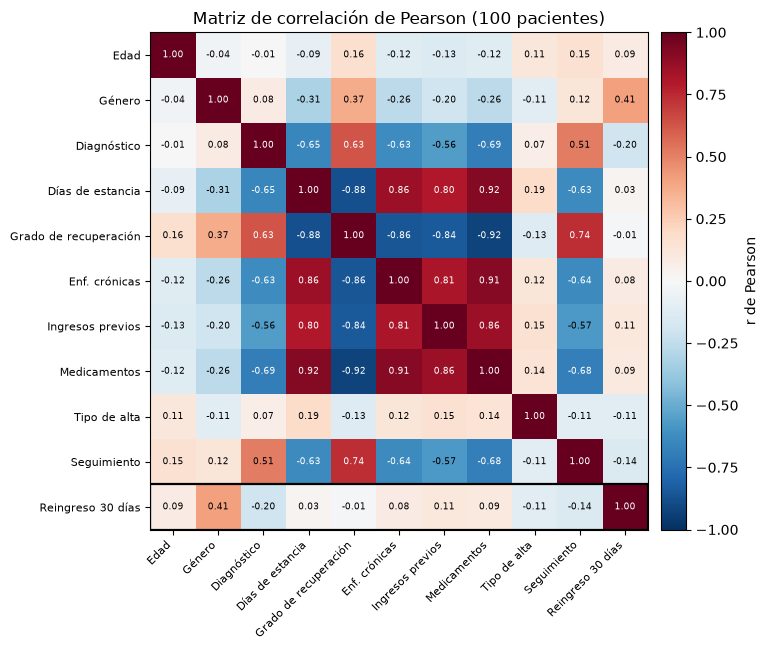

In [5]:
def clasifica(v):
    a = abs(v)
    f = 'nula' if a < 0.2 else 'débil' if a < 0.4 else 'moderada' if a < 0.7 else 'fuerte'
    return f if f == 'nula' else f"{f} {'+' if v > 0 else '−'}"

C = E.corr()
corr = C[RESP].drop(RESP)
display(pd.DataFrame({'r': corr.round(2), 'Tipo de relación': corr.map(clasifica)}))
print('Correlación del género con las variables clínicas:',
      C.loc['Género', ['Grado de recuperación', 'Enf. crónicas', 'Días de estancia', 'Medicamentos']].round(2).to_dict())

fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(C.values, cmap='RdBu_r', vmin=-1, vmax=1)
cols = list(E.columns)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(cols)), cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = C.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6.5, color='white' if abs(v) > 0.6 else 'black')
ax.add_patch(plt.Rectangle((-0.5, len(cols) - 1.5), len(cols), 1, fill=False, lw=1.6, ec='black'))
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='r de Pearson')
ax.set_title('Matriz de correlación de Pearson (100 pacientes)')
plt.tight_layout(); plt.show()

## 5. Árbol de decisión como auditor
El árbol **no sustituye al agente**: sus reglas legibles muestran qué aprendería cualquier modelo con estos datos.

* **Hiperparámetros:** se fijan antes de entrenar (profundidad, tamaño mínimo de hoja, criterio…).
* **Parámetros:** los aprende el árbol (qué variable pregunta cada nodo, con qué umbral y qué responde cada hoja).

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

HIPER = dict(criterion='gini', max_depth=3, min_samples_leaf=3, random_state=0)
DEMOG = [VARS.index('Edad'), G]

def arbol(idx=None, **hp):
    idx = np.arange(N) if idx is None else idx
    return DecisionTreeClassifier(**{**HIPER, **hp}).fit(X_all[idx], y_all[idx])

def loo_arbol(**hp):
    return round(100 * np.mean([arbol(np.delete(np.arange(N), i), **hp).predict(X_all[[i]])[0] == y_all[i]
                                for i in range(N)]))

ARB = arbol()
print(export_text(ARB, feature_names=VARS, class_names=['No reingresa', 'Reingresa']))
pd.Series(ARB.get_params(), name='valor').to_frame()

|--- Género <= 1.50
|   |--- Edad <= 64.50
|   |   |--- Enf. crónicas <= 1.50
|   |   |   |--- class: No reingresa
|   |   |--- Enf. crónicas >  1.50
|   |   |   |--- class: No reingresa
|   |--- Edad >  64.50
|   |   |--- Tipo de alta <= 1.50
|   |   |   |--- class: Reingresa
|   |   |--- Tipo de alta >  1.50
|   |   |   |--- class: No reingresa
|--- Género >  1.50
|   |--- Diagnóstico <= 9.50
|   |   |--- Seguimiento <= 0.50
|   |   |   |--- class: Reingresa
|   |   |--- Seguimiento >  0.50
|   |   |   |--- class: Reingresa
|   |--- Diagnóstico >  9.50
|   |   |--- class: No reingresa



,valor
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,3
max_features,None
max_leaf_nodes,None
min_impurity_decrease,0.0
min_samples_leaf,3
min_samples_split,2
min_weight_fraction_leaf,0.0


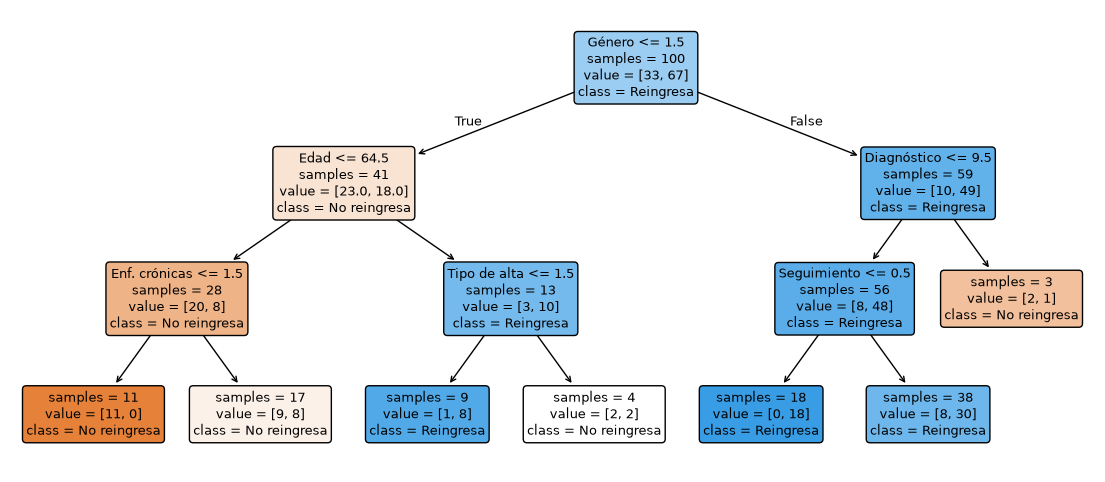

,Importancia
Edad,0.23
Género,0.41
Diagnóstico,0.09
Días de estancia,0.00
Grado de recuperación,0.00
Enf. crónicas,0.16
Ingresos previos,0.00
Medicamentos,0.00
Tipo de alta,0.05
Seguimiento,0.06


Edad + género: 64 %


In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(ARB, ax=ax, feature_names=VARS, class_names=['No reingresa', 'Reingresa'],
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.show()

imp = pd.Series(ARB.feature_importances_, index=VARS).round(2)
display(imp.to_frame('Importancia'))
print('Edad + género:', round(100 * imp.iloc[DEMOG].sum()), '%')

### ¿Qué hiperparámetro cambia la conclusión?
Se cambia un hiperparámetro a la vez; exactitud dejando uno fuera.

In [8]:
VARIANTES = {'Configuración elegida': {}, 'max_depth = 1': dict(max_depth=1), 'max_depth = 2': dict(max_depth=2),
             'max_depth = 5': dict(max_depth=5), 'max_depth = None': dict(max_depth=None),
             'min_samples_leaf = 1': dict(min_samples_leaf=1), 'min_samples_leaf = 5': dict(min_samples_leaf=5),
             'criterion = entropy': dict(criterion='entropy'), 'class_weight = balanced': dict(class_weight='balanced')}
filas = {}
for nombre, hp in VARIANTES.items():
    t = arbol(**hp)
    filas[nombre] = {'Exactitud %': loo_arbol(**hp), 'Hojas': t.get_n_leaves(), 'Raíz': VARS[t.tree_.feature[0]],
                     'Edad + género %': round(100 * t.feature_importances_[DEMOG].sum())}
pd.DataFrame(filas).T

,Exactitud %,Hojas,Raíz,Edad + género %
Configuración elegida,76,7,Género,64
max_depth = 1,72,2,Género,100
max_depth = 2,78,4,Género,88
max_depth = 5,60,12,Género,63
max_depth = None,65,20,Género,60
min_samples_leaf = 1,79,8,Género,60
min_samples_leaf = 5,73,7,Género,73
criterion = entropy,76,7,Género,59
class_weight = balanced,69,7,Género,64


## 6. Agente basado en distancias: inicial frente a propuesto
* **Agente inicial:** 10 variables, incluido el género.
* **Agente propuesto:** excluye el género de la distancia (el género solo se usa para auditar).

Ambos usan los 5 casos más parecidos y responden por mayoría. El agente propuesto agrega la explicación y el
**indicador de validez**: consenso de los 5 casos y distancia al más cercano.
* Verde: 5 de 5 y d < 0.50 → aceptar · Amarillo: 4 de 5 y d < 0.50 → revisar · Rojo: 3 de 5 o d ≥ 0.50 → rechazar.

In [9]:
K, REVISAR = 5, 0.50
AGENTES = {'Inicial': list(range(len(VARS))), 'Propuesto': SIN_GENERO}

def norm(X, cols):
    return (np.asarray(X, float)[..., cols] - MRANGE[cols, 0]) / (MRANGE[cols, 1] - MRANGE[cols, 0])

def AgenteXAI(x, cols=SIN_GENERO, excluir=None):
    idx = np.array([i for i in range(N) if i != excluir])
    d = np.sqrt(((norm(X_all[idx], cols) - norm(x, cols)) ** 2).sum(1))
    orden = np.argsort(d, kind='stable')[:K]
    vec, dk = idx[orden], d[orden]
    votos = int(y_all[vec].sum())
    resp = int(votos * 2 > K)
    consenso = votos if resp else K - votos
    if consenso == K and dk[0] < REVISAR:
        color = 'VERDE: aceptar'
    elif consenso == K - 1 and dk[0] < REVISAR:
        color = 'AMARILLO: revisar'
    else:
        color = 'ROJO: rechazar'
    dif2 = (norm(X_all[vec[0]], cols) - norm(x, cols)) ** 2
    aporte = dif2 / dif2.sum() * 100 if dif2.sum() > 0 else dif2
    return dict(resp=resp, consenso=consenso, vec=vec, d=dk, color=color, aporte=aporte)

PRED = {a: np.array([AgenteXAI(X_all[i], cols, excluir=i)['resp'] for i in range(N)]) for a, cols in AGENTES.items()}

## 7. Matrices de confusión, métricas por grupo y prueba contrafactual
Cada paciente se consulta contra los otros 99 y se compara con su desenlace registrado. El error más grave es el
**falso no reingresa** (FN); la métrica principal es la **sensibilidad** = VP / (VP + FN), que debe ser similar entre
grupos (igualdad de oportunidades).

In [10]:
HOMBRE, MUJER, MAYOR = X_all[:, G] == 2, X_all[:, G] == 1, X_all[:, 0] >= 65
GRUPOS = {'Global': np.ones(N, bool), 'Hombres': HOMBRE, 'Mujeres': MUJER, '65 o más': MAYOR, 'Menos de 65': ~MAYOR}

def metricas(yt, yp):
    vp = int(((yt == 1) & (yp == 1)).sum()); fn = int(((yt == 1) & (yp == 0)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum()); vn = int(((yt == 0) & (yp == 0)).sum())
    pct = lambda a, b: round(100 * a / b) if b else np.nan
    return {'n': len(yt), 'VP': vp, 'FN': fn, 'FP': fp, 'VN': vn, 'Exactitud %': pct(vp + vn, len(yt)),
            'Sensibilidad %': pct(vp, vp + fn), 'Especificidad %': pct(vn, vn + fp), 'Precisión %': pct(vp, vp + fp)}

tabla_met = pd.DataFrame({(a, g): metricas(y_all[m], PRED[a][m]) for a in AGENTES for g, m in GRUPOS.items()}).T
tabla_met

n  VP  FN  FP  VN  Exactitud %  Sensibilidad %  Especificidad %  Precisión %
Inicial   Global       100  57  10  17  16           73              85               48           77
          Hombres       59  48   1  10   0           81              98                0           83
          Mujeres       41   9   9   7  16           61              50               70           56
          65 o más      33  22   4   5   2           73              85               29           81
          Menos de 65   67  35   6  12  14           73              85               54           74
Propuesto Global       100  54  13  22  11           65              81               33           71
          Hombres       59  40   9   8   2           71              82               20           83
          Mujeres       41  14   4  14   9           56              78               39           50
          65 o más      33  23   3   4   3           79              88               43           85
          Menos de 65   67  31  10  18   8           58              76               31           63

[10 rows x 9 columns]

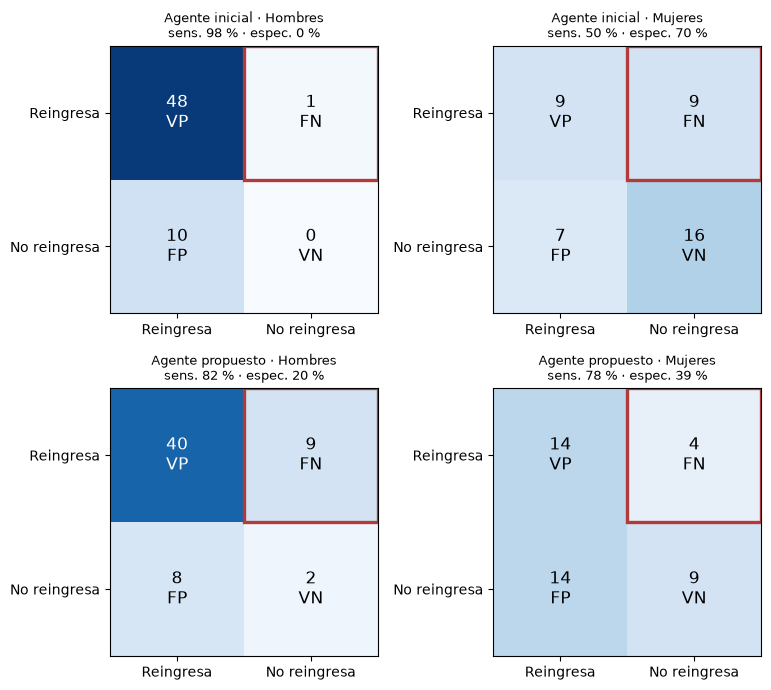

,Brecha de sensibilidad H vs. M (puntos),% de respuestas que cambian al invertir el género
Inicial,48,61
Propuesto,4,0


In [11]:
fig, axs = plt.subplots(2, 2, figsize=(8, 7))
for fila, a in enumerate(AGENTES):
    for col, (g, m) in enumerate([('Hombres', HOMBRE), ('Mujeres', MUJER)]):
        r_ = metricas(y_all[m], PRED[a][m]); ax = axs[fila, col]
        M = np.array([[r_['VP'], r_['FN']], [r_['FP'], r_['VN']]])
        ax.imshow(M, cmap='Blues', vmin=0, vmax=50)
        for i, et in enumerate([['VP', 'FN'], ['FP', 'VN']]):
            for j, e in enumerate(et):
                ax.text(j, i, f'{M[i, j]}\n{e}', ha='center', va='center', fontsize=12,
                        color='white' if M[i, j] > 28 else 'black')
        ax.add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, lw=2.4, ec='#b23a3a'))
        ax.set_xticks([0, 1], ['Reingresa', 'No reingresa']); ax.set_yticks([0, 1], ['Reingresa', 'No reingresa'])
        ax.set_title(f"Agente {a.lower()} · {g}\nsens. {r_['Sensibilidad %']} % · espec. {r_['Especificidad %']} %", fontsize=9)
plt.tight_layout(); plt.show()

def contrafactual(cols, pred):
    cambios = 0
    for i in range(N):
        x = X_all[i].copy(); x[G] = 3 - x[G]
        cambios += AgenteXAI(x, cols, excluir=i)['resp'] != pred[i]
    return round(100 * cambios / N)

brecha = {a: abs(tabla_met.loc[(a, 'Hombres'), 'Sensibilidad %'] - tabla_met.loc[(a, 'Mujeres'), 'Sensibilidad %'])
          for a in AGENTES}
pd.DataFrame({'Brecha de sensibilidad H vs. M (puntos)': brecha,
              '% de respuestas que cambian al invertir el género': {a: contrafactual(c, PRED[a]) for a, c in AGENTES.items()}})

## 8. Indicador de validez del agente propuesto (prueba dejando uno fuera)

In [12]:
res = [AgenteXAI(X_all[i], SIN_GENERO, excluir=i) for i in range(N)]
ok = np.array([a['resp'] for a in res]) == y_all
color = np.array([a['color'].split(':')[0] for a in res])
consenso = np.array([a['consenso'] for a in res])
display(pd.DataFrame({c: {'Pacientes': int((color == c).sum()), 'Concuerdan': int(ok[color == c].sum()),
                          'Concordancia %': round(100 * ok[color == c].mean())} for c in ['VERDE', 'AMARILLO', 'ROJO']}).T)
pd.DataFrame({f'{c} de 5': {'Pacientes': int((consenso == c).sum()), 'Concordancia %': round(100 * ok[consenso == c].mean())}
              for c in [5, 4, 3]}).T

,Pacientes,Concuerdan,Concordancia %
VERDE,16,13,81
AMARILLO,29,20,69
ROJO,55,32,58


,Pacientes,Concordancia %
5 de 5,18,83
4 de 5,32,69
3 de 5,50,56


## 9. Casos de uso

In [13]:
def explicar(x, titulo):
    a = AgenteXAI(np.array(x, float))
    print(f"=== {titulo} ===")
    print(f"Respuesta: {'REINGRESA' if a['resp'] else 'NO REINGRESA'} | consenso: {a['consenso']} de 5 "
          f"| distancia al más cercano: {a['d'][0]:.3f} | {a['color']}")
    j = a['vec'][0]
    aporte = dict(zip([VARS[c] for c in SIN_GENERO], a['aporte'].round(1)))
    display(pd.DataFrame({'Paciente nuevo': x, f'Caso más cercano ({df.ID[j]})': X_all[j].astype(int),
                          'Aporte a d (%)': [aporte.get(v, 'no se usa') for v in VARS]}, index=VARS))
    vec = df.iloc[a['vec']][['ID', 'Edad', 'Genero', 'Diagnostico', 'Recuperacion', 'Cronicas',
                             'IngresosPrev', 'Seguimiento', 'Reingreso']].copy()
    vec.insert(1, 'd', a['d'].round(3))
    print('Los 5 casos más parecidos:')
    display(vec.reset_index(drop=True))

# Caso 1: mujer de 80 años, EPOC, 11 días, recuperación baja, 3 crónicas, 2 ingresos previos,
#         8 medicamentos, alta con cuidados, sin seguimiento
explicar([80, 1, 4, 11, 1, 3, 2, 8, 2, 0], 'Caso 1')

=== Caso 1 ===
Respuesta: REINGRESA | consenso: 5 de 5 | distancia al más cercano: 0.100 | VERDE: aceptar


,Paciente nuevo,Caso más cercano (P076),Aporte a d (%)
Edad,80,77,17.4
Género,1,1,no se usa
Diagnóstico,4,4,0.0
Días de estancia,11,10,82.6
Grado de recuperación,1,1,0.0
Enf. crónicas,3,3,0.0
Ingresos previos,2,2,0.0
Medicamentos,8,8,0.0
Tipo de alta,2,2,0.0
Seguimiento,0,0,0.0


Los 5 casos más parecidos:


,ID,d,Edad,Genero,Diagnostico,Recuperacion,Cronicas,IngresosPrev,Seguimiento,Reingreso
0,P076,0.100,77,M,EPOC,Baja,3,2,No,Sí
1,P100,0.279,84,M,Pancreatitis,Baja,4,2,No,Sí
2,P062,0.460,83,H,Neumonía,Baja,4,3,No,Sí
3,P095,0.569,71,H,Fractura de fémur,Baja,3,2,No,Sí
4,P052,0.613,68,M,Insuficiencia cardiaca,Baja,3,2,No,Sí


In [14]:
# Caso 2: hombre de 40 años, apendicitis, 3 días, recuperación alta, 0 crónicas, 0 ingresos previos,
#         2 medicamentos, alta a domicilio, con seguimiento
explicar([40, 2, 7, 3, 3, 0, 0, 2, 1, 1], 'Caso 2')

=== Caso 2 ===
Respuesta: REINGRESA | consenso: 3 de 5 | distancia al más cercano: 0.195 | ROJO: rechazar


,Paciente nuevo,Caso más cercano (P027),Aporte a d (%)
Edad,40,43,4.6
Género,2,2,no se usa
Diagnóstico,7,8,32.5
Días de estancia,3,2,21.8
Grado de recuperación,3,3,0.0
Enf. crónicas,0,0,0.0
Ingresos previos,0,0,0.0
Medicamentos,2,1,41.1
Tipo de alta,1,1,0.0
Seguimiento,1,1,0.0


Los 5 casos más parecidos:


,ID,d,Edad,Genero,Diagnostico,Recuperacion,Cronicas,IngresosPrev,Seguimiento,Reingreso
0,P027,0.195,43,H,Fractura de tibia,Alta,0,0,Sí,Sí
1,P067,0.203,45,M,Infección urinaria,Alta,0,0,Sí,No
2,P032,0.206,47,H,Apendicitis,Alta,0,0,Sí,Sí
3,P004,0.208,30,H,Apendicitis,Alta,0,0,Sí,Sí
4,P059,0.215,38,H,Fractura de tibia,Alta,0,0,Sí,No
